In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# 2. Simulate firm-level panel data (500 firms, 2010-2023)
np.random.seed(42)
n_firms = 500
years = range(2010, 2024)

data = []
for firm_id in range(1, n_firms + 1):
    base_tfp = np.random.normal(10, 2)
    base_patents = np.random.poisson(2)

    for year in years:
        green_patents = max(0, base_patents + np.random.normal(0, 1) + (year - 2010) * 0.1)
        # We set the "true" effect of patents on TFP to be 0.05
        tfp = base_tfp + (0.05 * green_patents) + np.random.normal(0, 1)

        data.append({
            'firm_id': firm_id,
            'year': year,
            'green_patents': green_patents,
            'tfp': tfp
        })

df = pd.DataFrame(data)
print(f"✅ Dataset created with {len(df)} observations!")
print(df.head())

✅ Dataset created with 7000 observations!
   firm_id  year  green_patents        tfp
0        1  2010       1.861736  11.365556
1        1  2011       3.110515  10.568076
2        1  2012       1.674830  10.505790
3        1  2013       1.375917   8.449675
4        1  2014       3.350370  11.977392


In [2]:
# Run a fixed-effects model (Firm and Year)
model = smf.ols('tfp ~ green_patents + C(firm_id) + C(year)', data=df).fit()

coef = model.params['green_patents']
pval = model.pvalues['green_patents']

print(f"📈 Regression Results:")
print(f"-------------------------")
print(f"Coefficient for Green Patents: {coef:.4f}")
print(f"P-value: {pval:.4e}")

📈 Regression Results:
-------------------------
Coefficient for Green Patents: 0.0303
P-value: 1.7777e-02


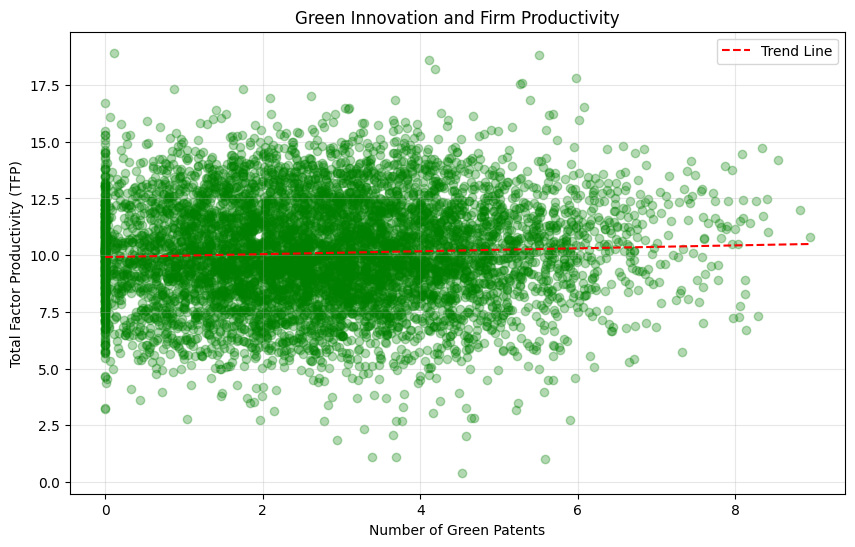

In [3]:
# Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df['green_patents'], df['tfp'], alpha=0.3, color='green')

# Add a trend line
z = np.polyfit(df['green_patents'], df['tfp'], 1)
p = np.poly1d(z)
plt.plot(df['green_patents'].sort_values(), p(df['green_patents'].sort_values()), "r--", label="Trend Line")

plt.title('Green Innovation and Firm Productivity')
plt.xlabel('Number of Green Patents')
plt.ylabel('Total Factor Productivity (TFP)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()